# 02 — Baselines vs model

Results of `scripts/run_evaluation.py`: configs chosen on 2023–24 by walk-forward log-loss, then evaluated once on the 2025–26 holdout (and on 2026 alone, the new regulation era). Every prediction comes from a model trained only on earlier races.

In [1]:
import json, os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.chdir(Path('..'))  # project root, so f1pred finds data/ and configs/
from f1pred.data import load_tables
from f1pred.evaluate import races_between, walk_forward, metrics
from f1pred.features import T1_FEATURES, T2_FEATURES, build_features
from f1pred.predict import load_spec

rep = json.loads(Path('reports/evaluation.json').read_text(encoding='utf-8'))
hold = pd.DataFrame(rep['holdout'])
rep['chosen']

{'t1': {'kind': 'logreg', 'params': {'C': 0.03}, 'same_era_weight': 1.0},
 't2': {'kind': 'lgbm',
  'params': {'n_estimators': 200, 'num_leaves': 7, 'min_child_samples': 60},
  'same_era_weight': 3.0}}

## Holdout results

In [2]:
cols = ['stage', 'window', 'model', 'winner_acc', 'podium_hit', 'logloss_win', 'brier_win', 'races']
hold[cols].round(3)

,stage,window,model,winner_acc,podium_hit,logloss_win,brier_win,races
0,t1,holdout 2025–26,logreg,0.273,0.614,1.769,0.837,44.0
1,t1,holdout 2025–26,lgbm,0.318,0.614,1.775,0.824,44.0
2,t1,holdout 2025–26,B2 leader wins,0.273,0.523,5.024,1.454,44.0
3,t1,holdout 2025–26,B2p P(win | standings),0.273,0.576,1.891,0.830,44.0
4,t1,2026 only,logreg,0.300,0.567,1.882,0.858,20.0
5,t1,2026 only,lgbm,0.300,0.583,1.887,0.846,20.0
6,t1,2026 only,B2 leader wins,0.350,0.433,4.490,1.300,20.0
7,t1,2026 only,B2p P(win | standings),0.350,0.467,1.965,0.827,20.0
8,t2,holdout 2025–26,logreg,0.546,0.697,1.140,0.579,44.0
9,t2,holdout 2025–26,lgbm,0.568,0.712,1.059,0.544,44.0


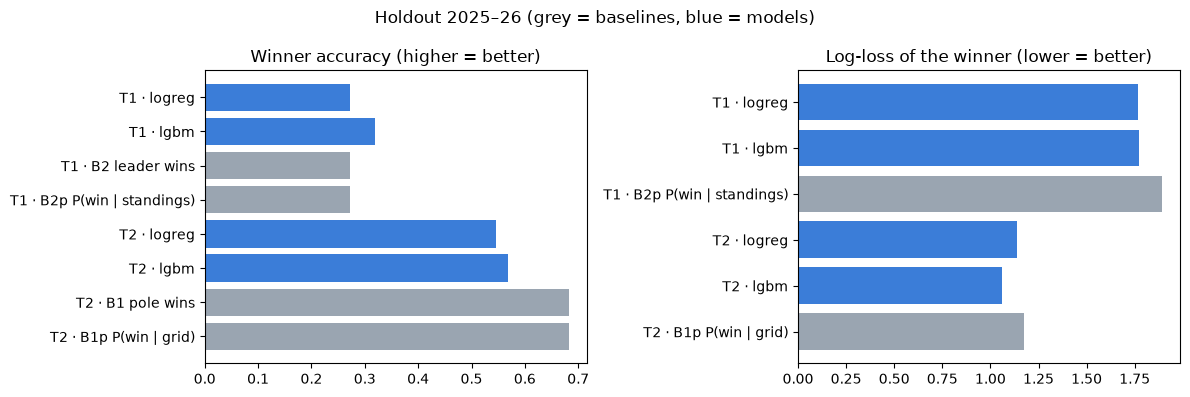

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], 'winner_acc', 'Winner accuracy (higher = better)'),
                          (axes[1], 'logloss_win', 'Log-loss of the winner (lower = better)')]:
    sub = hold[hold.window == 'holdout 2025–26'].copy()
    sub['label'] = sub['stage'].str.upper() + ' · ' + sub['model']
    sub = sub[~(sub['model'].str.startswith('B') & ~sub['model'].str.contains('p '))
              | (metric == 'winner_acc')]
    colors = ['#9aa5b1' if m.startswith('B') else '#3b7dd8' for m in sub['model']]
    ax.barh(sub['label'], sub[metric], color=colors)
    ax.set_title(title)
    ax.invert_yaxis()
plt.suptitle('Holdout 2025–26 (grey = baselines, blue = models)')
plt.tight_layout()

Deterministic baselines (0/1 predictions) have a huge log-loss by construction, so the log-loss panel compares the models against the *calibrated* baselines (`B1p`, `B2p`: empirical P(win | grid) and P(win | standings)).

## Calibration of P(win) — chosen T2 model, 2025–26

,predicted,observed,n
bin,,,
"(0.0, 0.05]",0.005,0.003,770
"(0.05, 0.15]",0.087,0.033,61
"(0.15, 0.3]",0.208,0.281,32
"(0.3, 0.5]",0.390,0.429,28
"(0.5, 0.7]",0.600,0.609,23
"(0.7, 1.0]",0.735,1.000,5


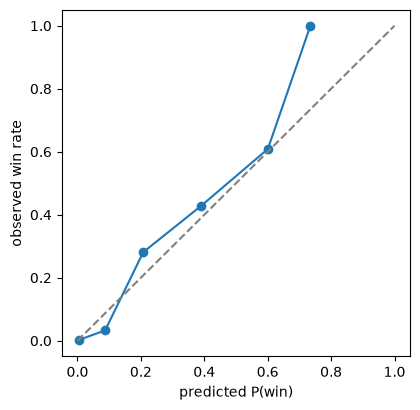

In [4]:
t = load_tables()
frame = build_features(t)
spec2 = load_spec('t2', Path('configs'))
preds = walk_forward(frame, spec2.as_predictor(), races_between(frame, 2025, 2026))
bins = [0, 0.05, 0.15, 0.3, 0.5, 0.7, 1.0]
preds['bin'] = pd.cut(preds['p_win'], bins)
cal = preds.groupby('bin', observed=True).agg(predicted=('p_win', 'mean'),
                                              observed=('win', 'mean'), n=('win', 'size'))
ax = cal.plot(x='predicted', y='observed', marker='o', legend=False, figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], ls='--', c='grey')
ax.set_xlabel('predicted P(win)'); ax.set_ylabel('observed win rate')
cal.round(3)

## 2026 race by race — chosen T2 model

In [5]:
p26 = preds[preds.season == 2026]
top = p26.sort_values('p_win').groupby('round').tail(1).set_index('round')
act = p26[p26.win == 1].set_index('round')
pd.DataFrame({'predicted': top['driver_id'], 'p_top': top['p_win'].round(2),
              'actual': act['driver_id'], 'p_actual': act['p_win'].round(2),
              'actual_grid': act['grid_f']}).sort_index()

,predicted,p_top,actual,p_actual,actual_grid
round,,,,,
1,russell,0.58,russell,0.58,1.0
2,russell,0.35,antonelli,0.30,1.0
3,antonelli,0.68,antonelli,0.68,1.0
4,antonelli,0.64,antonelli,0.64,1.0
5,russell,0.62,antonelli,0.16,2.0
6,antonelli,0.67,antonelli,0.67,1.0
7,russell,0.42,hamilton,0.15,2.0
8,russell,0.61,russell,0.61,1.0
9,antonelli,0.67,leclerc,0.04,2.0


## What the models rely on

In [6]:
def importance(stage):
    spec = load_spec(stage, Path('configs'))
    train = frame[frame['win'].notna()]
    fitted = spec.fit(train, 2026)['win']
    if spec.kind == 'lgbm':
        imp = pd.Series(fitted.booster_.feature_importance('gain'), index=spec.features)
        return (imp / imp.sum()).sort_values(ascending=False).head(12).rename('gain share')
    coefs = fitted.named_steps['logisticregression'].coef_[0][:len(spec.features)]
    return pd.Series(coefs, index=spec.features).sort_values(key=abs, ascending=False)\
        .head(12).rename('std. coefficient')

pd.concat({'T1': importance('t1').reset_index(), 'T2': importance('t2').reset_index()},
          axis=1)

T1                                       T2           
                    index std. coefficient                   index gain share
0      drv_quali_gap_ewm5        -0.292942               grid_norm   0.346034
1         drv_points_ewm5         0.266664           quali_gap_pct   0.107906
2     team_quali_gap_ewm5        -0.232878         quali_rank_norm   0.100679
3            cs_pts_share         0.215706         drv_finish_ewm3   0.046582
4           drv_grid_ewm5        -0.211076         drv_points_ewm5   0.036707
5                 drv_age        -0.193866            cs_pts_share   0.033466
6            ds_pts_share         0.175915               front_row   0.029487
7   team_best_finish_ewm5        -0.174462            ds_pts_share   0.027916
8         drv_finish_ewm8        -0.163366      drv_quali_gap_ewm5   0.027688
9      fp_longrun_gap_pct        -0.158176           drv_grid_ewm5   0.027466
10    drv_mech_dnf_rate20         0.157027  teammate_quali_gap_pct   0.020284
11       team_points_ewm5         0.151379        team_points_ewm5   0.016861